<div style="background-color: #1b4f72; padding: 30px; border-radius: 8px; text-align: center;">
    <h2 style="color: white; font-weight: bold; margin: 0;">MOVIMIENTO BROWNIANO CON DERIVA</h2>
</div>

# Formulación del problema

La probabilidad de que el movimiento browniano con parámetro de deriva $\mu = 0.6$ y varianza $\sigma^2 = 0.25$ tome valores entre $1$ y $3$ al tiempo $t = 4$.

El movimiento browniano con deriva se define como:

$$X(t) = \mu t + \sigma W(t)$$

Donde $W(t)$ es un movimiento browniano estándar. Suponemos que $X(0) = 0$.

Sabemos que:

$$W(t) \sim \mathcal{N}(0, t)$$

Por lo tanto:

$$X(t) \sim \mathcal{N}(\mu t, \sigma^2 t)$$

### Se calcula la media y varianza al tiempo 4.

Media

$$\mu t = (0.6)(4) = 2.4$$

Varianza

$$\sigma^2 t = (0.25)(4) = 1$$

Así

$$X(4) \sim \mathcal{N}(2.4, 1)$$

### Se estandariza utilizando la distribución normal

$$P(1 < X(4) < 3)$$

Se utiliza

$$Z = \frac{X - \mu t}{\sigma \sqrt{t}}$$

Sustituyendo:

$$P\left(\frac{1 - 2.4}{1} < Z < \frac{3 - 2.4}{1}\right) = P(-1.4 < Z < 0.6)$$

Se calcula la probabilidad 

$$P = P(Z < 0.6) - P(Z < -1.4)$$

$$P = 0.725747 - 0.080757$$

$$P = 0.644990$$

La probabilidad de que el movimiento browniano con deriva esté entre 1 y 3 al tiempo 4 es 64.50%.

# Codigo

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu = 0.6
sigma_cuadrado = 0.25
sigma = np.sqrt(sigma_cuadrado)

t_final = 4
limite_inferior = 1
limite_superior = 3

### Solución analitica

In [2]:
# Media y varianza del movimiento browniano
media = mu * t_final
varianza = sigma_cuadrado * t_final
desviacion = np.sqrt(varianza)

# Estandarización
z_inferior = (limite_inferior - media) / desviacion
z_superior = (limite_superior - media) / desviacion

# Probabilidad usando la distribución normal
p_analitica = norm.cdf(z_superior) - norm.cdf(z_inferior)

print("Media:", media)
print("Varianza:", varianza)
print("Z inferior:", z_inferior)
print("Z superior:", z_superior)
print(f"Probabilidad analítica: {p_analitica:.6f}")
print(f"Porcentaje: {p_analitica*100:.2f}%")

Media: 2.4
Varianza: 1.0
Z inferior: -1.4
Z superior: 0.6000000000000001
Probabilidad analítica: 0.644990
Porcentaje: 64.50%


### Simulación de Monte Carlo

In [3]:
# Semilla para reproducibilidad
rng = np.random.default_rng(42)

num_trayectorias = 50000
num_pasos = 200

dt = t_final / num_pasos

tiempos = np.linspace(0, t_final, num_pasos + 1)

# Incrementos del movimiento browniano
delta_w = rng.normal(
    0,
    np.sqrt(dt),
    size=(num_trayectorias, num_pasos)
)

# Valor del movimiento browniano al tiempo 4
w_final = np.sum(delta_w, axis=1)

x_final = mu * t_final + sigma * w_final

# Contar valores entre 1 y 3
favorables = (x_final > 1) & (x_final < 3)

num_favorables = np.sum(favorables)

# Probabilidad simulada
p_simulada = num_favorables / num_trayectorias

print("Trayectorias simuladas:", num_trayectorias)
print("Casos favorables:", num_favorables)
print(f"Probabilidad simulada: {p_simulada:.6f}")
print(f"Porcentaje: {p_simulada*100:.2f}%")


Trayectorias simuladas: 50000
Casos favorables: 32242
Probabilidad simulada: 0.644840
Porcentaje: 64.48%


### Gráfica de las trayectorias

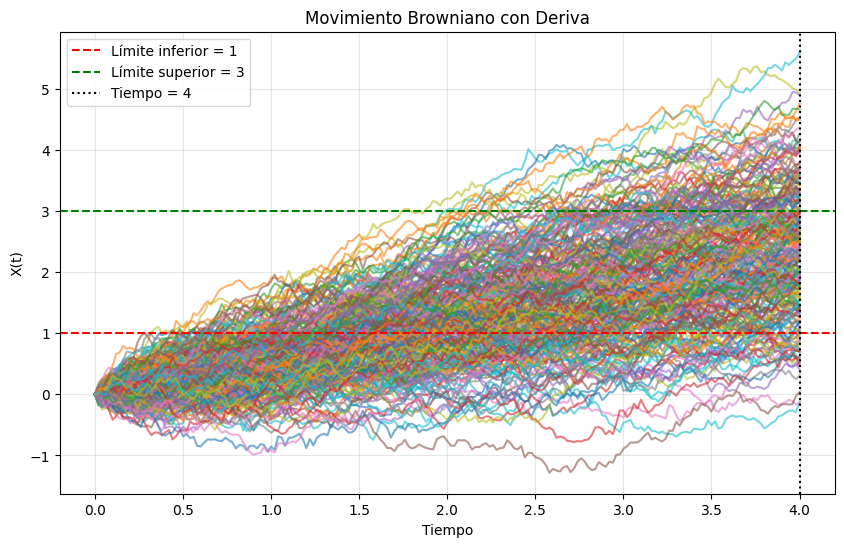

In [7]:
# Graficar trayectorias
mostrar = 250

w_trayectorias = np.column_stack([
    np.zeros(mostrar),
    np.cumsum(delta_w[:mostrar, :], axis=1)
])

x_trayectorias = (
    mu * tiempos[np.newaxis, :]
    + sigma * w_trayectorias
)

plt.figure(figsize=(10, 6))

for trayectoria in x_trayectorias:
    plt.plot(tiempos, trayectoria, alpha=0.6)

plt.axhline(1, color="red", linestyle="--",
            label="Límite inferior = 1")

plt.axhline(3, color="green", linestyle="--",
            label="Límite superior = 3")

plt.axvline(4, color="black", linestyle=":",
            label="Tiempo = 4")

plt.xlabel("Tiempo")
plt.ylabel("X(t)")
plt.title("Movimiento Browniano con Deriva")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Gráfica de la distribucion normal

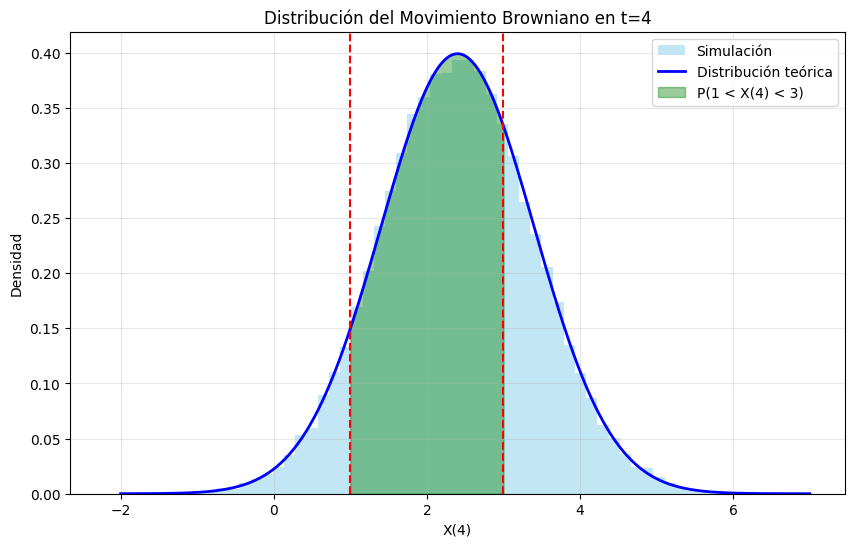

In [8]:
plt.figure(figsize=(10, 6))

# Histograma de los valores simulados
plt.hist(
    x_final,
    bins=60,
    density=True,
    alpha=0.5,
    color="skyblue",
    label="Simulación"
)

# Distribución normal teórica
x = np.linspace(-2, 7, 500)
y = norm.pdf(x, media, desviacion)

plt.plot(x, y, color="blue", linewidth=2,
         label="Distribución teórica")

# Región de probabilidad
x_region = np.linspace(1, 3, 200)
y_region = norm.pdf(x_region, media, desviacion)

plt.fill_between(
    x_region,
    y_region,
    color="green",
    alpha=0.4,
    label="P(1 < X(4) < 3)"
)

plt.axvline(1, color="red", linestyle="--")
plt.axvline(3, color="red", linestyle="--")

plt.title("Distribución del Movimiento Browniano en t=4")
plt.xlabel("X(4)")
plt.ylabel("Densidad")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Comparación de resultados

In [9]:
error_absoluto = abs(p_analitica - p_simulada)

print("COMPARACIÓN DE RESULTADOS")
print("-------------------------")

print(f"Probabilidad analítica: {p_analitica:.6f}")
print(f"Probabilidad simulada:  {p_simulada:.6f}")
print(f"Error absoluto:         {error_absoluto:.6f}")

print("\nCONCLUSIÓN")

print(
    "La probabilidad de que el movimiento browniano "
    "con deriva tome valores entre 1 y 3 al tiempo 4 "
    f"es aproximadamente {p_analitica*100:.2f}%."
)


COMPARACIÓN DE RESULTADOS
-------------------------
Probabilidad analítica: 0.644990
Probabilidad simulada:  0.644840
Error absoluto:         0.000150

CONCLUSIÓN
La probabilidad de que el movimiento browniano con deriva tome valores entre 1 y 3 al tiempo 4 es aproximadamente 64.50%.
